# How the Soft TPR slot swap works

We choose a shared slot reordering from training examples, apply it to each validation token's own fillers, and add the difference between the two decoded representations. This notebook repeats the layer-20 calibration and a small CPU example using the frozen checkpoint and cached states, then reads the saved Qwen results. It calls the experiment helpers without rerunning Qwen.

The recorded experiment edits both nouns together at layers 20–22, one layer per forward pass, at α = 1 with unmatched norms. The [results notebook](native_tpr_steering_results.ipynb) provides baseline preferences, agent − patient logits, bidirectional flips, and subgroup filters.


## Load the run

Run from the repository root or `notebook/` with the experiment environment (`/tmp/tpr-binding-gpu-venv/bin/python` here). Dependencies are recorded in `environment-packages.json`. These calculations use CPU and two PyTorch threads.

The default is `ac-tpr-cache/native-tpr-nov6-20261108`; set `AC_TPR_NATIVE_RUN` to use another copy. The frozen reference artifacts must be available for the hash checks. Figures stay inline; tables and provenance go to `notebook/figures/native_soft_tpr_slot_swap/`.


In [1]:
%matplotlib inline
from pathlib import Path
from types import SimpleNamespace
from collections import Counter
import json
import math
import os
import sys
import time
from importlib.metadata import version


In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").is_file(), "Run from the repository root or notebook directory"
configured_run = os.environ.get("AC_TPR_NATIVE_RUN")
RUN = (Path(configured_run).expanduser().resolve() if configured_run else
       ROOT / "ac-tpr-cache/native-tpr-nov6-20261108")
for directory in (ROOT / "src", ROOT / "scripts/temporary", Path("/tmp/ac-tpr-nov6-extra")):
    if directory.is_dir() and str(directory) not in sys.path:
        sys.path.insert(0, str(directory))


In [3]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
from run_tpr_nov6 import digest, torch_load
from run_native_tpr_nov6 import load_plan, verify_calibration, pair_rows, read_csv, summarize
from native_soft_interventions import encode_native_soft, select_slot_permutation, native_slot_swap
from diagnose_native_tpr_nov6 import simulate_local_edit, require_completed_evaluation


/tmp/tpr-binding-gpu-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Plot settings


In [4]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#94a3b8",
    "axes.labelcolor": "#334155",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "figure.dpi": 130,
})
FIGURES = ROOT / "notebook/figures/native_soft_tpr_slot_swap"
FIGURES.mkdir(parents=True, exist_ok=True)

def show_figure(fig):
    """Display the figure inline and release its plotting resources."""
    plt.show()
    plt.close(fig)


### Check the saved experiment


In [5]:
torch.set_num_threads(2)
pd.set_option("display.max_colwidth", 90)
declared = json.loads((RUN / "plan.json").read_text())
args = SimpleNamespace(run_dir=RUN, batch_size=declared["batch_size"])
plan, reference = load_plan(args)
verify_calibration(args)
frozen_source_hashes = dict(plan["source_sha256"])
calibration_metadata_hash = digest(RUN / "calibration/metadata.json")
evaluation_metadata = require_completed_evaluation(RUN, plan["layers"])
diagnostic_metadata = json.loads((RUN / "diagnostics/metadata.json").read_text())
assert diagnostic_metadata["status"] == "complete"
assert digest(ROOT / "scripts/temporary/diagnose_native_tpr_nov6.py") == diagnostic_metadata["diagnostic_script_sha256"]
for relative_path, expected in diagnostic_metadata["input_sha256"].items():
    assert digest(RUN / relative_path) == expected, relative_path
for relative_path, expected in diagnostic_metadata["files_sha256"].items():
    assert digest(RUN / "diagnostics" / relative_path) == expected, relative_path


### Run settings and package versions


In [6]:
display(pd.DataFrame([
    {"Field": "Model", "Value": plan["model"]},
    {"Field": "Model revision", "Value": plan["revision"]},
    {"Field": "Run", "Value": str(RUN)},
    {"Field": "Layers", "Value": str(plan["layers"])},
    {"Field": "Alpha", "Value": str(plan["fixed_alpha"])},
    {"Field": "Norm matching", "Value": str(plan["norm_matching"])},
    {"Field": "Verified scientific source files", "Value": str(len(frozen_source_hashes))},
]))

current_runtime = {"python": sys.version.split()[0], "torch": str(torch.__version__),
                   "cuda": torch.version.cuda, "transformers": version("transformers"),
                   "nnsight": version("nnsight")}
display(pd.DataFrame([{
    "Runtime component": name, "Frozen experiment": value,
    "Current notebook": current_runtime[name],
} for name, value in plan["runtime"].items()]))


,Field,Value
0,Model,Qwen/Qwen3-8B-Base
1,Model revision,49e3418fbbbca6ecbdf9608b4d22e5a407081db4
2,Run,/home/ldomenichelli/Workspace/AC-TPR-native-nov6/ac-tpr-cache/native-tpr-nov6-20261108
3,Layers,"[20, 21, 22]"
4,Alpha,1.0
5,Norm matching,False
6,Verified scientific source files,15


,Runtime component,Frozen experiment,Current notebook
0,python,3.12.3,3.12.3
1,torch,2.13.0+cu130,2.13.0+cu130
2,cuda,13.0,13.0
3,transformers,5.9.0,5.9.0
4,nnsight,0.7.0,0.7.0


## What is in a Soft TPR representation?

The autoencoder maps a normalized token state to a soft tensor. It unbinds that tensor with **eight fixed orthonormal role vectors**, then quantizes the eight fillers with one shared learned codebook. A learned decoder maps the bound tensor back to hidden-state space.

The slots have no assigned agent/patient labels, and code indices are not word identities. We keep the checkpoint's codebook, decoder, and role buffers, loading its `config`, `state_dict`, `center`, and `scale`.


In [7]:
source = torch_load(reference / "extraction/states.pt")
assert source["layers"] == plan["layers"]
assert source["states"].dtype == torch.bfloat16
counts = Counter(row["split"] for row in source["rows"])
assert dict(counts) == plan["expected_counts"]

LAYER = 20
layer_index = source["layers"].index(LAYER)
payload = torch_load(Path(plan["soft_reference_run"]) / f"training/layer_{LAYER}.pt")
stored_calibration = json.loads((RUN / f"calibration/layer_{LAYER}.json").read_text())
config = payload["config"]
roles = payload["state_dict"]["roles"].float()
assert roles.shape == (config["role_dim"], config["num_roles"])
torch.testing.assert_close(roles.T @ roles, torch.eye(config["num_roles"]), rtol=1e-5, atol=1e-5)

display(pd.DataFrame([{"Parameter": name, "Value": value} for name, value in config.items()]))
display(pd.DataFrame([
    {"Split": split, "Sentences": count, "Noun tokens": 2 * count}
    for split, count in sorted(counts.items())
]))
print("Cached hidden-state shape:", tuple(source["states"].shape))
print("Axis order: sentence, layer, [agent, patient], hidden coordinate")


,Parameter,Value
0,input_dim,4096
1,hidden_dim,256
2,num_roles,8
3,role_dim,16
4,filler_dim,32
5,num_codes,64


,Split,Sentences,Noun tokens
0,gen_test,1680,3360
1,test,416,832
2,train,3300,6600
3,val,412,824


Cached hidden-state shape: (5808, 3, 2, 4096)
Axis order: sentence, layer, [agent, patient], hidden coordinate


## Choose a slot reordering from training pairs

Pair each training noun token with the same filler in the opposite role, using its quad's same-voice swapped sentence. `pair_rows` checks these training pairs. Validation and held-out edits need no donor tokens.

For quantized fillers $q$, choose one permutation $p$ per layer to minimize

$$\sum_{i,k}\|q_{i,p(k)}-q_{\mathrm{twin}(i),k}\|_2^2.$$

The selected permutation is shared across both voices and both token roles.


### Search and tie breaking

Search all **764 involutions of eight slots**, including identity. An involution undoes itself when applied twice. Candidates within relative tolerance $10^{-12}$ of the minimum tie; prefer fewer moved slots, then lexicographic order.

Below we repeat calibration on all **3,300 training sentences / 6,600 noun tokens at layer 20**, checking the permutation, objective, and cost matrix against the saved run.


In [8]:
train_ids = [i for i, row in enumerate(source["rows"]) if row["split"] == "train"]
donor_token_ids = pair_rows(source["rows"], train_ids)
saved_pairing = json.loads((RUN / "calibration/train_pairing.json").read_text())
assert saved_pairing["split"] == "train"
assert train_ids == saved_pairing["row_ids"]
assert donor_token_ids.tolist() == saved_pairing["donor_token_local_ids"]
assert len(train_ids) == plan["calibration"]["sentences"]
assert len(donor_token_ids) == plan["calibration"]["tokens"]


In [9]:
started = time.perf_counter()
train_h = source["states"][train_ids, layer_index].float().flatten(0, 1)
train_q, train_codes = encode_native_soft(payload, train_h)
recomputed_permutation, recomputed_diagnostics = select_slot_permutation(train_q, train_q[donor_token_ids])
assert recomputed_permutation == stored_calibration["permutation"]
assert recomputed_diagnostics["candidate_count"] == stored_calibration["diagnostics"]["candidate_count"] == 764
assert math.isclose(
    recomputed_diagnostics["best"]["objective_sse"],
    stored_calibration["diagnostics"]["best"]["objective_sse"],
    rel_tol=1e-12, abs_tol=1e-9,
)
torch.testing.assert_close(
    torch.tensor(recomputed_diagnostics["cost_matrix"], dtype=torch.float64),
    torch.tensor(stored_calibration["diagnostics"]["cost_matrix"], dtype=torch.float64),
    rtol=1e-12, atol=1e-9,
)
print(f"Verified full-training calibration in {time.perf_counter() - started:.1f} seconds.")
display(pd.DataFrame([
    {"Candidate": label, **recomputed_diagnostics[label]}
    for label in ("identity", "best", "second")
]))
print("Relative training MSE reduction:", recomputed_diagnostics["relative_improvement"])


Verified full-training calibration in 0.3 seconds.


,Candidate,permutation,objective_sse,mse,moved_slots
0,identity,"[0, 1, 2, 3, 4, 5, 6, 7]",581137.130612,0.343950,0
1,best,"[5, 1, 2, 3, 4, 0, 6, 7]",554963.952648,0.328459,2
2,second,"[5, 6, 2, 3, 4, 0, 1, 7]",567471.886607,0.335862,4


Relative training MSE reduction: 0.04503786900778436


In [10]:
calibration_rows = []
for layer in plan["layers"]:
    record = json.loads((RUN / f"calibration/layer_{layer}.json").read_text())
    detail = record["diagnostics"]
    calibration_rows.append({
        "Layer": layer,
        "Permutation (output slot receives input slot)": record["permutation"],
        "Training tokens": record["training_tokens"],
        "Moved slots": detail["best"]["moved_slots"],
        "Identity MSE": detail["identity"]["mse"],
        "Selected MSE": detail["best"]["mse"],
        "Training MSE reduction (%)": 100 * detail["relative_improvement"],
        "Recomputed in this notebook": layer == LAYER,
    })
display(pd.DataFrame(calibration_rows))
del train_h, train_q, train_codes


,Layer,Permutation (output slot receives input slot),Training tokens,Moved slots,Identity MSE,Selected MSE,Training MSE reduction (%),Recomputed in this notebook
0,20,"[5, 1, 2, 3, 4, 0, 6, 7]",6600,2,0.343950,0.328459,4.503787,True
1,21,"[3, 1, 2, 0, 4, 5, 6, 7]",6600,2,0.341753,0.334690,2.066812,False
2,22,"[0, 1, 2, 5, 4, 3, 6, 7]",6600,2,0.336197,0.317008,5.707692,False


## Decode the change

For a token, normalize $x=(h-c)/s$ and obtain its quantized fillers $q$. Reorder them as $q^*_k=q_{p(k)}$. The helper computes

$$\Delta h=s\,W_{\mathrm{decoder}}\,\operatorname{vec}\!\left(\operatorname{bind}(q^*-q)\right).$$

This is the difference between decoding the reordered and original representations. We use the learned decoder here; no pseudoinverse is needed. Its bias cancels, and adding the difference to the original hidden state preserves the reconstruction residual.


### What is preserved?

Reordering keeps the target's multiset of code indices and filler vectors exactly. Re-encoding the edited state can give different codes, and neither the target nor its recovery guarantees word identity or a changed answer in Qwen.

At α = 1, both nouns receive the same slot permutation, with a different delta for each token and no extra agent/patient sign. Norms are not matched. The GPU run adds both edits at the live hook using directions computed from cached baseline states.


## Try a few validation tokens

Take the first two validation sentences per voice in corpus order, independently of outcomes, and use both noun tokens. The helper simulates `BF16(h.float() + delta).float()` locally. These are not live hook captures. No held-out examples or donors construct the edits.


In [11]:
demo_ids = [
    i
    for voice in ("active", "passive")
    for i in [j for j, row in enumerate(source["rows"])
              if row["split"] == "val" and row["voice"] == voice][:2]
]
assert len(demo_ids) == 4
assert all(source["rows"][i]["split"] == "val" for i in demo_ids)
demo_rows = [source["rows"][i] for i in demo_ids]
display(pd.DataFrame([
    {"Row ID": row_id, "Voice": row["voice"], "Sentence": row["sentence"],
     "Agent": row["agent"], "Patient": row["patient"]}
    for row_id, row in zip(demo_ids, demo_rows)
]))


,Row ID,Voice,Sentence,Agent,Patient
0,48,active,John kicked Peter.,John,Peter
1,50,active,Peter kicked John.,Peter,John
2,49,passive,Peter was kicked by John.,John,Peter
3,51,passive,John was kicked by Peter.,Peter,John


### Apply the permutation

Keep each token's own fillers and change only their slot assignment.


In [12]:
h = source["states"][demo_ids, layer_index].float().flatten(0, 1)
permutation = stored_calibration["permutation"]
q_before, codes_before = encode_native_soft(payload, h)
delta, intervention_diagnostics = native_slot_swap(payload, h, permutation)
h_after = simulate_local_edit(h, delta)
q_after, codes_after = encode_native_soft(payload, h_after)
target_q = q_before[:, permutation]
target_codes = codes_before[:, permutation]
assert torch.equal(target_codes.sort(1).values, codes_before.sort(1).values)
assert torch.equal(target_q[:, permutation], q_before)
assert delta.shape == h.shape
assert plan["fixed_alpha"] == 1.0 and plan["norm_matching"] is False
print("Native intervention diagnostics:")
display(pd.DataFrame([{"Diagnostic": name, "Value": str(value)}
                      for name, value in intervention_diagnostics.items()]))


Native intervention diagnostics:


,Diagnostic,Value
0,tokens,8
1,permutation,"[5, 1, 2, 3, 4, 0, 6, 7]"
2,moved_slots,2
3,code_multiset_preserved,True
4,latent_double_swap_exact,True
5,fraction_changed_codes,0.25
6,zero_native_edit_fraction,0.0
7,mean_hidden_edit_norm,44.56012991725097
8,min_hidden_edit_norm,29.605709596642857
9,max_hidden_edit_norm,59.487355675049024


### Compare with the saved validation edits

The local token norms should match the recorded ones.


In [13]:
validation_metadata = json.loads((RUN / "validation/metadata.json").read_text())
assert validation_metadata["status"] == "complete"
assert digest(RUN / "validation/results.csv") == validation_metadata["results_sha256"]
validation_records = read_csv(RUN / "validation/results.csv")
recorded_demo = {
    int(record["row_id"]): record
    for record in validation_records
    if record["method"] == "soft_native_slot_swap" and int(record["layer"]) == LAYER
    and int(record["row_id"]) in demo_ids
}
assert set(recorded_demo) == set(demo_ids)


In [14]:
token_details = []
for sentence_index, (row_id, row) in enumerate(zip(demo_ids, demo_rows)):
    for role_index, role in enumerate(("agent", "patient")):
        token_index = 2 * sentence_index + role_index
        norm = float(delta[token_index].double().norm())
        assert math.isclose(norm, float(recorded_demo[row_id][role + "_edit_norm"]), rel_tol=1e-6, abs_tol=1e-10)
        token_details.append({
            "Row ID": row_id, "Voice": row["voice"], "Source role": role, "Filler": row[role],
            "Edit norm": norm,
            "Original codes": codes_before[token_index].tolist(),
            "Target codes": target_codes[token_index].tolist(),
            "Re-encoded codes": codes_after[token_index].tolist(),
            "All target slots recovered": bool(torch.equal(codes_after[token_index], target_codes[token_index])),
            "Re-encoded code multiset preserved": bool(torch.equal(
                codes_after[token_index].sort().values, codes_before[token_index].sort().values)),
        })
display(pd.DataFrame(token_details))
print("All demonstration edit norms match the original validation result records.")


,Row ID,Voice,Source role,Filler,Edit norm,Original codes,Target codes,Re-encoded codes,All target slots recovered,Re-encoded code multiset preserved
0,48,active,agent,John,40.257548,"[9, 38, 8, 28, 42, 60, 2, 11]","[60, 38, 8, 28, 42, 9, 2, 11]","[60, 38, 8, 28, 42, 33, 2, 11]",False,False
1,48,active,patient,Peter,46.812989,"[5, 23, 32, 32, 33, 33, 51, 13]","[33, 23, 32, 32, 33, 5, 51, 13]","[61, 44, 32, 32, 33, 5, 55, 13]",False,False
2,50,active,agent,Peter,29.605710,"[43, 12, 8, 32, 33, 32, 2, 11]","[32, 12, 8, 32, 33, 43, 2, 11]","[32, 12, 8, 32, 33, 62, 2, 11]",False,False
3,50,active,patient,John,46.812989,"[5, 23, 32, 28, 62, 33, 51, 13]","[33, 23, 32, 28, 62, 5, 51, 13]","[33, 44, 8, 28, 62, 5, 55, 13]",False,False
4,49,passive,agent,John,59.487356,"[44, 23, 32, 28, 62, 12, 51, 8]","[12, 23, 32, 28, 62, 44, 51, 8]","[12, 23, 32, 28, 62, 62, 51, 8]",False,False
5,49,passive,patient,Peter,33.759545,"[43, 12, 0, 32, 33, 27, 2, 0]","[27, 12, 0, 32, 33, 43, 2, 0]","[62, 12, 0, 32, 33, 51, 2, 0]",False,False
6,51,passive,agent,Peter,59.487356,"[44, 23, 32, 32, 33, 12, 51, 8]","[12, 23, 32, 32, 33, 44, 51, 8]","[12, 23, 32, 32, 33, 62, 51, 8]",False,False
7,51,passive,patient,John,40.257548,"[9, 38, 0, 28, 42, 60, 2, 37]","[60, 38, 0, 28, 42, 9, 2, 37]","[60, 38, 0, 28, 42, 61, 2, 37]",False,False


All demonstration edit norms match the original validation result records.


### Compare recovery with doing nothing

Moving two of eight slots already leaves six target slots matched before editing (**75%**). Equal codes in the moved slots can raise that baseline.

Compare target construction, recovery after re-encoding, and code-multiset retention separately. Only the target's exact multiset preservation is guaranteed by the permutation; these checks do not establish lexical preservation in Qwen.


In [15]:
fixed_slots = sum(slot == source_slot for slot, source_slot in enumerate(permutation))
no_edit_slot_match = (codes_before == target_codes).double().mean(1)
assert (no_edit_slot_match >= fixed_slots / len(permutation)).all()

display(pd.DataFrame([
    {
        "Representation": label,
        "Mean target slot match (%)": 100 * float((codes == target_codes).double().mean()),
        "Tokens with every target slot (%)": 100 * float((codes == target_codes).all(1).double().mean()),
        "Tokens preserving original code multiset (%)": 100 * float(
            (codes.sort(1).values == codes_before.sort(1).values).all(1).double().mean()),
        "Tokens": len(codes),
    }
    for label, codes in (
        ("Original / no edit", codes_before),
        ("Permuted latent target", target_codes),
        ("Re-encoded local BF16 edit", codes_after),
    )
]))
print(f"Unchanged-slot lower bound: {fixed_slots}/{len(permutation)} = {100 * fixed_slots / len(permutation):.1f}%")


,Representation,Mean target slot match (%),Tokens with every target slot (%),Tokens preserving original code multiset (%),Tokens
0,Original / no edit,75.0000,0.0,100.0,8
1,Permuted latent target,100.0000,100.0,100.0,8
2,Re-encoded local BF16 edit,79.6875,0.0,0.0,8


Unchanged-slot lower bound: 6/8 = 75.0%


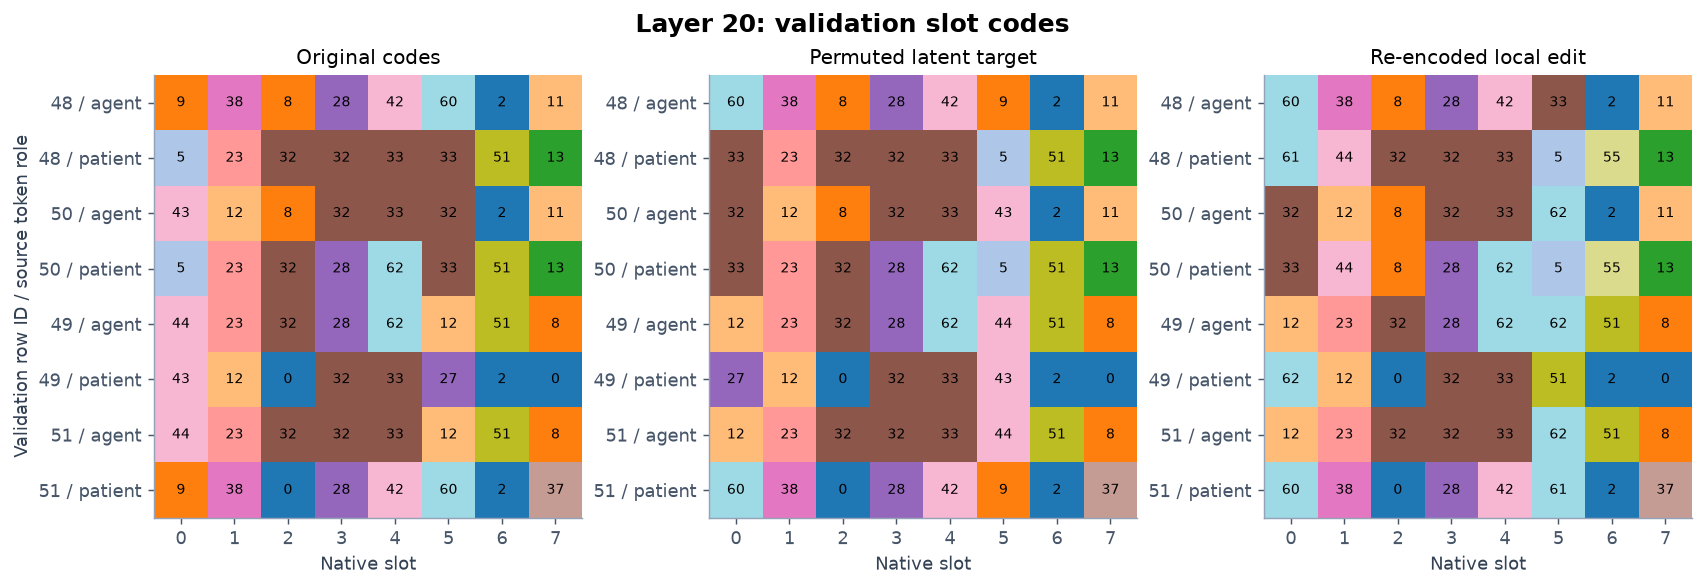

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), constrained_layout=True)
for axis, title, codes in zip(
    axes,
    ("Original codes", "Permuted latent target", "Re-encoded local edit"),
    (codes_before, target_codes, codes_after),
):
    axis.imshow(codes.numpy(), aspect="auto", interpolation="nearest", cmap="tab20", vmin=0, vmax=config["num_codes"] - 1)
    for token_index in range(len(codes)):
        for slot in range(config["num_roles"]):
            axis.text(slot, token_index, str(int(codes[token_index, slot])), ha="center", va="center", fontsize=8)
    axis.set(title=title, xlabel="Native slot", xticks=range(config["num_roles"]))
    axis.set_yticks(range(len(codes)))
    axis.set_yticklabels([f"{row['Row ID']} / {row['Source role']}" for row in token_details])
axes[0].set_ylabel("Validation row ID / source token role")
fig.suptitle(f"Layer {LAYER}: validation slot codes", fontsize=14, weight="bold")
show_figure(fig)


## What happens to the model answers?

The saved evaluation edits both nouns together at one layer and scores the original agent and patient answers. `summarize` aggregates the rows by split and voice. Here the **conditional flip rate** is strict agent → patient flips divided by **baseline agent wins**. Ties do not count.

All methods use α = 1 with unmatched norms. Layers 20–22 were chosen from historical raw-steering peaks, so this is exploratory. Raw-centroid results were reused after exact baseline checks and scored sentinels, recorded in `result_origin`. No uncertainty intervals are estimated.

The [results notebook](native_tpr_steering_results.ipynb) gives bidirectional flips, agent − patient logits, and subgroup filters.


In [17]:
heldout_records = read_csv(RUN / "evaluation/results.csv")
assert len(heldout_records) == evaluation_metadata["result_rows"]
assert len({int(row["row_id"]) for row in heldout_records}) == evaluation_metadata["rows"]
assert all(float(row["alpha"]) == 1.0 for row in heldout_records)
heldout_summary = pd.DataFrame(summarize(heldout_records))
assert len(heldout_summary) == len(plan["layers"]) * len(plan["methods"]) * 2 * 2
soft_summary = heldout_summary[heldout_summary["method"] == "soft_native_slot_swap"].copy()
soft_summary["conditional_flip_percent"] = 100 * soft_summary["conditional_flip"]
display(soft_summary[[
    "split", "voice", "layer", "sentences", "baseline_agent_wins", "flips", "conditional_flip_percent",
    "mean_agent_edit_norm", "mean_patient_edit_norm", "zero_token_edits",
]].sort_values(["split", "voice", "layer"]).reset_index(drop=True))
print("Full saved evaluation rows:", len(heldout_records))
print("Distinct held-out sentences:", evaluation_metadata["rows"])
display(pd.DataFrame(heldout_records).groupby(["method", "result_origin"]).size().rename("Recorded rows").reset_index())


,split,voice,layer,sentences,baseline_agent_wins,flips,conditional_flip_percent,mean_agent_edit_norm,mean_patient_edit_norm,zero_token_edits
0,gen_test,active,20,840,840,3,0.357143,44.500136,40.836624,5
1,gen_test,active,21,840,840,0,0.000000,44.709876,42.975672,18
2,gen_test,active,22,840,840,0,0.000000,53.067995,44.949791,4
3,gen_test,passive,20,840,839,168,20.023838,53.031627,44.669398,1
4,gen_test,passive,21,840,839,10,1.191895,34.755138,47.759616,2
5,gen_test,passive,22,840,839,0,0.000000,44.206476,54.044622,0
6,test,active,20,208,208,0,0.000000,47.054535,42.967325,2
7,test,active,21,208,208,0,0.000000,46.319297,41.487691,14
8,test,active,22,208,208,0,0.000000,50.369319,46.643588,0
9,test,passive,20,208,208,63,30.288462,55.801278,47.900430,0


Full saved evaluation rows: 18864
Distinct held-out sentences: 2096


,method,result_origin,Recorded rows
0,raw_centroid,reference_raw,6288
1,soft_native_slot_swap,scored,6288
2,tpr_native_role_swap,scored,6288


In [18]:
METHOD_LABELS = {
    "raw_centroid": "Raw centroid",
    "tpr_native_role_swap": "Native TPR role swap",
    "soft_native_slot_swap": "Native Soft TPR slot swap",
}
METHOD_COLORS = {
    "raw_centroid": "#64748b",
    "tpr_native_role_swap": "#0072B2",
    "soft_native_slot_swap": "#D55E00",
}
METHOD_STYLES = {
    "raw_centroid": "-",
    "tpr_native_role_swap": "--",
    "soft_native_slot_swap": "-.",
}


### Conditional flips across layers


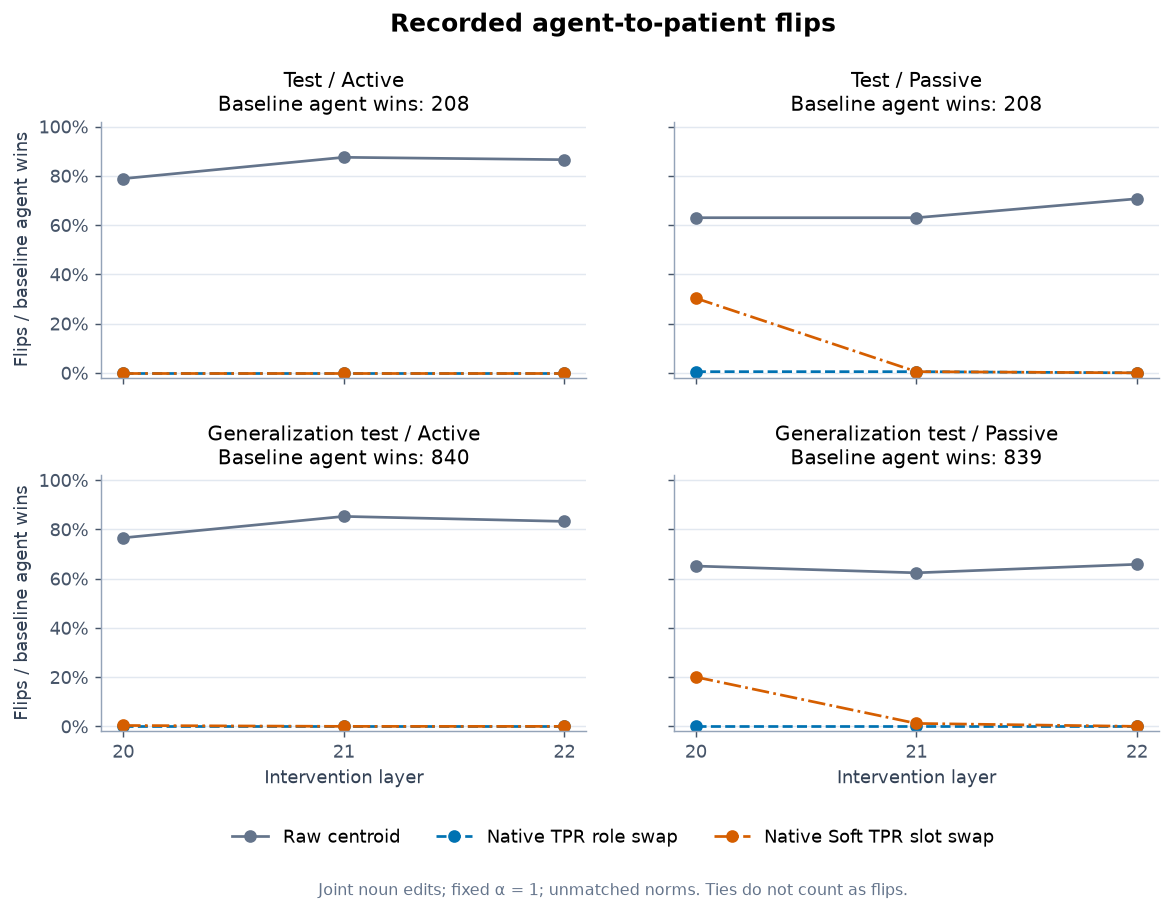

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7), sharex=True, sharey=True)
for axis, (split, voice) in zip(
    axes.flat, [(s, v) for s in ("test", "gen_test") for v in ("active", "passive")]
):
    cohort = heldout_summary[(heldout_summary["split"] == split) & (heldout_summary["voice"] == voice)]
    denominators = cohort["baseline_agent_wins"].unique()
    assert len(denominators) == 1
    for method in plan["methods"]:
        data = cohort[cohort["method"] == method].sort_values("layer")
        axis.plot(data["layer"], data["conditional_flip"], marker="o",
                  color=METHOD_COLORS[method], linestyle=METHOD_STYLES[method],
                  label=METHOD_LABELS[method])
    split_label = "Test" if split == "test" else "Generalization test"
    axis.set(title=f"{split_label} / {voice.capitalize()}\nBaseline agent wins: {int(denominators[0]):,}",
             xticks=plan["layers"], ylim=(-0.02, 1.02))
    axis.yaxis.set_major_formatter(PercentFormatter(1))
    axis.set_axisbelow(True)
    axis.grid(axis="y", color="#e2e8f0")
for axis in axes[-1]:
    axis.set_xlabel("Intervention layer")
for axis in axes[:, 0]:
    axis.set_ylabel("Flips / baseline agent wins")
fig.suptitle("Recorded agent-to-patient flips", fontsize=14, weight="bold", y=0.99)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center",
           bbox_to_anchor=(0.5, 0.055), ncol=3, frameon=False)
fig.text(0.5, 0.02, "Joint noun edits; fixed α = 1; unmatched norms. Ties do not count as flips.",
         ha="center", color="#64748b", fontsize=9)
fig.subplots_adjust(top=0.87, bottom=0.20, hspace=0.38, wspace=0.18)
show_figure(fig)


## Re-encoding across the held-out tokens

Now use the saved CPU diagnostics for all held-out cached tokens, separately from the validation example and Qwen answer scores. Select the `all` vocabulary cohort to avoid double-counting the additional `known` and `oov` rows.

Pool integer counts across token role and voice within each layer and split. Recovering every target slot is stricter than mean slot matching. Code-multiset retention ignores order; the target must preserve it, but the re-encoded edited state need not.


In [20]:
fidelity = pd.read_csv(RUN / "diagnostics/soft_fidelity.csv")
fidelity_all = fidelity[fidelity["vocabulary"] == "all"].copy()
pooled = fidelity_all.groupby(["layer", "split"], as_index=False)[[
    "tokens", "slot_matches", "total_slots", "all_codes_match_tokens",
    "bag_retained_tokens", "target_bag_preserved_tokens",
]].sum()
assert (pooled["target_bag_preserved_tokens"] == pooled["tokens"]).all()
pooled["Target slot match (%)"] = 100 * pooled["slot_matches"] / pooled["total_slots"]
pooled["Every target slot recovered (%)"] = 100 * pooled["all_codes_match_tokens"] / pooled["tokens"]
pooled["Original code multiset retained (%)"] = 100 * pooled["bag_retained_tokens"] / pooled["tokens"]
pooled["Latent target multiset preserved (%)"] = 100 * pooled["target_bag_preserved_tokens"] / pooled["tokens"]
display(pooled[[
    "layer", "split", "tokens", "Target slot match (%)", "Every target slot recovered (%)",
    "Original code multiset retained (%)", "Latent target multiset preserved (%)",
]])


,layer,split,tokens,Target slot match (%),Every target slot recovered (%),Original code multiset retained (%),Latent target multiset preserved (%)
0,20,gen_test,3360,67.232143,7.291667,7.321429,100.0
1,20,test,832,82.031250,17.427885,17.548077,100.0
2,21,gen_test,3360,62.176339,4.940476,5.059524,100.0
3,21,test,832,80.078125,12.860577,13.100962,100.0
4,22,gen_test,3360,69.769345,9.077381,9.761905,100.0
5,22,test,832,84.990986,21.394231,23.557692,100.0


## Save the tables

Save calibration, validation diagnostics, held-out summaries, and provenance. Recheck the scientific sources, calibration, and recorded evaluation. Figures stay inline.


In [21]:
for relative_path, expected in frozen_source_hashes.items():
    assert digest(ROOT / relative_path) == expected, relative_path
assert digest(RUN / "calibration/metadata.json") == calibration_metadata_hash
verify_calibration(args)
assert digest(RUN / "evaluation/results.csv") == evaluation_metadata["results_sha256"]
print(f"Verified: all {len(frozen_source_hashes)} frozen scientific sources are unchanged.")
print("Verified: original calibration and recorded held-out evaluation are unchanged.")
print("This notebook did not retrain models, rerun Qwen, or write experiment artifacts.")


Verified: all 15 frozen scientific sources are unchanged.
Verified: original calibration and recorded held-out evaluation are unchanged.
This notebook did not retrain models, rerun Qwen, or write experiment artifacts.


In [22]:
pd.DataFrame(calibration_rows).to_csv(FIGURES / "slot_calibration.csv", index=False)
pd.DataFrame(token_details).to_csv(FIGURES / "validation_token_diagnostics.csv", index=False)
heldout_summary.to_csv(FIGURES / "heldout_statistics.csv", index=False)
pooled.to_csv(FIGURES / "heldout_reencoding.csv", index=False)


In [23]:
provenance = {
    "run_directory": str(RUN.resolve()),
    "model": plan["model"],
    "revision": plan["revision"],
    "layers": plan["layers"],
    "calibration_recomputed_layer": LAYER,
    "validation_demo_row_ids": demo_ids,
    "fixed_alpha": plan["fixed_alpha"],
    "norm_matching": plan["norm_matching"],
    "edited_roles": ["agent", "patient"],
    "edit_protocol": "Both noun tokens jointly; one intervention layer per forward pass",
    "conditional_flip": "Strict agent-to-patient flips / baseline agent wins; ties do not count",
    "local_diagnostics": "CPU simulation of BF16(h.float() + delta).float(); no live Qwen inference",
    "slot_codes": "Code indices are not lexical identities",
    "uncertainty": "Descriptive curves; no uncertainty intervals",
    "notebook_runtime": current_runtime,
    "scientific_source_sha256": frozen_source_hashes,
    "artifact_sha256": {
        name: digest(RUN / name)
        for name in ("plan.json", "calibration/metadata.json", "evaluation/metadata.json",
                     "evaluation/results.csv", "validation/metadata.json", "validation/results.csv",
                     "diagnostics/metadata.json", "diagnostics/soft_fidelity.csv")
    },
}
(FIGURES / "plot_metadata.json").write_text(json.dumps(provenance, indent=2) + "\n")
print(f"Tables and provenance saved to {FIGURES}")


Tables and provenance saved to /home/ldomenichelli/Workspace/AC-TPR-native-nov6/notebook/figures/native_soft_tpr_slot_swap


## Reading the results

A slot permutation specifies a latent edit without assigning semantic role labels to the slots. Read the answer changes alongside edit norms and re-encoding diagnostics; the permutation alone does not guarantee recovery or word identity in Qwen.

See the [TPR walkthrough](native_tpr_role_swap.ipynb), [comparative results](native_tpr_steering_results.ipynb), or [experiment report](../ac-tpr-cache/native-tpr-nov6-20261108/report/report.md) for the full protocol.
